# TASK -1

### 1. Data Access & Familiarization  :


In [1]:
import numpy as np
import pandas as pd

In [2]:
df= pd.read_excel("ApexPlanet_DataAnalytics_Dataset.xlsx")

In [3]:
df.shape

(1000, 12)

In [4]:
# checking the first 5 rows
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [5]:
# data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


| Variable Name | Data Type | Description | Analytical Relevance |
| :--- | :--- | :--- | :--- |
| **`Order_ID`** | Object / String | Unique alphanumeric identifier for each order transaction | Transaction tracking . |
| **`Order_Date`** | Object / Date | Timestamp/date when the order was placed (Year 2025) | Seasonality, monthly patterns. |
| **`Customer_ID`** | Object / String | Unique identifier assigned to each consumer | Customer retention and repeat purchase behavior. |
| **`Customer_Name`**| Object / String | Masked customer name (e.g., `Customer_227`) | Anonymized reference identifier. |
| **`Age`** | Float64 / Numeric | Age of the purchasing customer in years (Range: 18 - 65) | Demographic segmentation and age cohort analysis. |
| **`Gender`** | Object / Binary | Gender classification of the customer (`Male`, `Female`) | Gender preference and category affinity evaluation. |
| **`City`** | Object / Nominal | Fulfillment delivery destination city | Geographic distribution and regional demand mapping. |
| **`Product`** | Object / Nominal | Product purchased (Mobile, Book, Laptop, Chair, Shoes, Rice) | product volume, and basket composition. |
| **`Category`** | Object / Nominal | Commercial vertical (Electronics, Education, Furniture, Fashion, Grocery) | Strategic merchandise planning and inventory allocation. |
| **`Quantity`** | Int64 / Discrete | Number of units purchased in the order (Range: 1 - 10) | Order volume, bulk purchasing, and pricing elasticities. |
| **`Unit_Price`** | Float64 / Continuous| Price per single unit of the product in INR | Pricing tiers. |
| **`Total_Sales`** | Float64 / Continuous| Total monetary transaction value (`Quantity * Unit_Price`) | Primary target variable for predictive machine learning. |



### 2. Data Quality Assessment  :

In [6]:
# checking null values
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64

In [7]:
df[df['Order_ID'].duplicated()]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
118,ORD100050,2025-01-22,CUST3194,Customer_114,34.0,Male,Kolkata,Book,Education,2,25795.55,51591.10
238,ORD100050,2025-03-01,CUST8467,Customer_104,23.0,Male,Bengaluru,Book,Education,3,2860.83,8582.49
358,ORD100050,2025-02-11,CUST6467,Customer_181,24.0,Female,Pune,Rice,Grocery,7,45480.39,318362.73
478,ORD100050,2025-11-22,CUST8225,Customer_468,64.0,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72
598,ORD100050,2025-02-21,CUST8859,Customer_53,NaN,Male,NaN,Laptop,Electronics,7,20144.84,141013.88
718,ORD100050,2025-11-06,CUST7824,Customer_190,31.0,Female,Mumbai,Rice,Grocery,4,42642.59,170570.36
838,ORD100050,2025-08-03,CUST5585,Customer_289,35.0,Male,Kolkata,Chair,Furniture,9,28747.47,258727.23
958,ORD100050,2025-02-09,CUST7188,Customer_89,62.0,Male,Bengaluru,Mobile,Electronics,1,34619.77,34619.77


In [8]:
df['Order_ID'].nunique()

992

##### OrderID contains duplicate values; however, they correspond to different transaction records and are not true duplicates. Since OrderID is an identifier and not a predictive feature, these records were retained without modification.

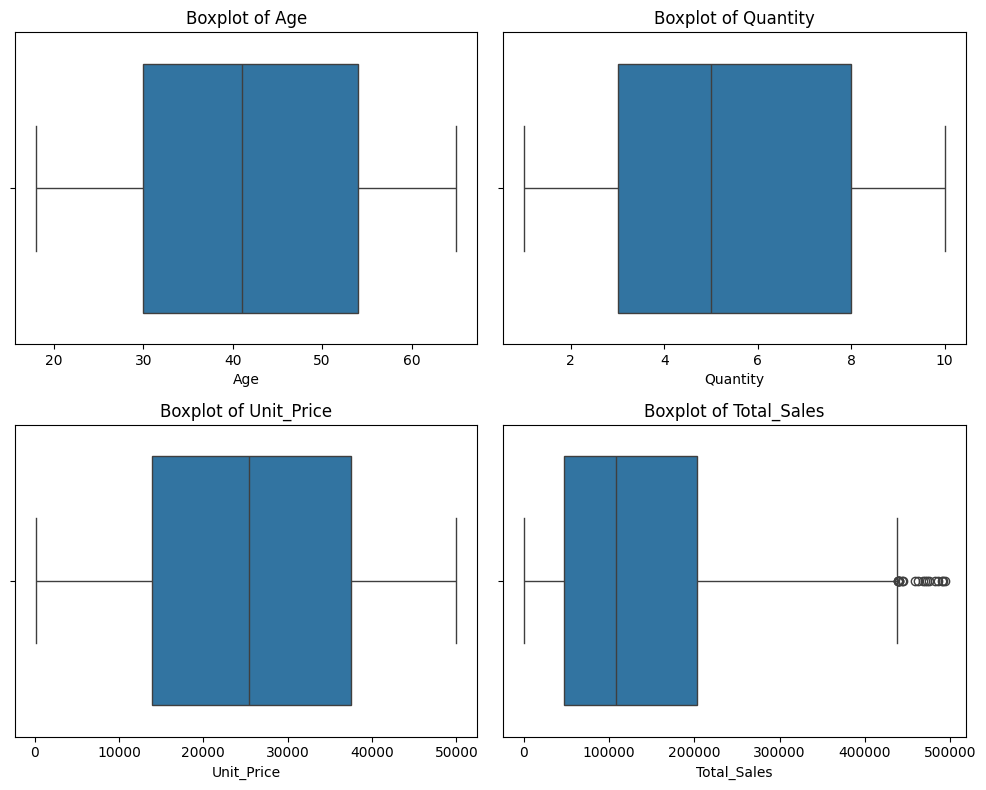

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
plot_num=1
plt.figure(figsize=(10,8))
for col in numerical_cols:
    plt.subplot(2,2,plot_num)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plot_num +=1
plt.tight_layout()
plt.show()

In [10]:
q1 = df['Total_Sales'].quantile(0.25)
q3 = df['Total_Sales'].quantile(0.75)

IQR = q3-q1
lower_bound = q1 - 1.5*IQR
upper_bound = q3 + 1.5*IQR

outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

print(f"{col}: {len(outliers)} outliers")

Total_Sales: 19 outliers


### 3. Data Cleaning & Transformation :

#### Replacing Null Value

In [11]:
print(df['Age'].min())
print(df['Age'].max())

18.0
65.0


In [12]:
common_age = df['Age'].value_counts().idxmax()
common_age_count = df['Age'].value_counts().max()
print(common_age , common_age_count)

30.0 35


In [13]:
# Replace all the null value of age with median value
df['Age']= df['Age'].fillna(df['Age'].median()).astype(int)

In [14]:
# checking cities available in our dataset
df['City'].value_counts()

City
Patna        135
Kolkata      133
Mumbai       131
Hyderabad    125
Delhi        125
Bengaluru    122
Gaya         117
Pune          99
Name: count, dtype: int64

In [15]:
df['City'] = df['City'].fillna('Pune')

In [16]:
# Checking NUll values after replacing
df.isnull().sum()

Order_ID         0
Order_Date       0
Customer_ID      0
Customer_Name    0
Age              0
Gender           0
City             0
Product          0
Category         0
Quantity         0
Unit_Price       0
Total_Sales      0
dtype: int64

#### Sort the dataset in chronological order based on Order_Date

In [17]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

In [18]:
df = df.sort_values(by='Order_Date').reset_index(drop =True)

**The dataset was sorted chronologically using the Order_Date column to maintain the correct sequence of transactions. The index was then reset to generate a clean and continuous row numbering after sorting, improving data organization and ensuring consistency for time-based analysis and feature engineering.**

In [19]:
import warnings
warnings.filterwarnings('ignore')

# **TASK -2**

## **Exploratory Data Analysis (EDA) & Business Intelligence**

## Descriptive Statistics 

In [20]:
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales
count,1000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.353000,5.435000,25486.783410,139399.439650
min,2025-01-01 00:00:00,18.000000,1.000000,145.780000,437.340000
25%,2025-03-30 18:00:00,30.000000,3.000000,13895.722500,47066.632500
50%,2025-07-01 00:00:00,41.000000,5.000000,25398.740000,108594.025000
75%,2025-10-07 06:00:00,53.000000,8.000000,37512.382500,203722.882500
max,2026-01-01 00:00:00,65.000000,10.000000,49997.530000,493677.500000
std,NaN,13.683626,2.838632,14179.402361,114100.051546


**Interpretation of Numerical Fields** 
* **Age:** Spans legal adult ages from 18 to 65 years with an average of 41.35 and median of 41.00. The distribution is nearly symmetric (skewness = +0.04) and Platykurtic (kurtosis = -1.20), indicating a uniform spread across adult age brackets without heavy tail concentrations. There were 20 missing values (2%) and we did required imputation using median .
* **Quantity:** Ranges uniformly from 1 to 10 units per transaction, averaging 5.44 units. Half of all orders contain 5 or fewer items, while the upper quartile purchases 8 or more units.
* **Unit_Price:** Shows a synthetic-like uniform range between ₹145.78 and ₹49,997.53 (mean = ₹25,486.78; median = ₹25,398.74). Because unit pricing appears randomly distributed regardless of SKU (e.g., grocery items priced comparably to electronics), pricing patterns are uncorrelated with product tiers.
* **Total_Sales:** Strongly right-skewed (skewness = +0.99). While the median ticket size is ₹108,594.03, the mean is pulled upward to ₹139,399.44 by high-value transactions that peak at ₹493,677.50.

In [21]:
df.describe(include='O')

,Order_ID,Customer_ID,Customer_Name,Gender,City,Product,Category
count,1000,1000,1000,1000,1000,1000,1000
unique,992,947,425,2,8,6,5
top,ORD100050,CUST2515,Customer_359,Male,Patna,Mobile,Electronics
freq,9,3,8,511,135,184,354


In [51]:
city_dist = pd.DataFrame({
    'Count': df['City'].value_counts(),
    'Percentage': round(df['City'].value_counts(normalize=True) * 100, 2)
})

print(city_dist)

           Count  Percentage
City                        
Patna        135        13.5
Kolkata      133        13.3
Mumbai       131        13.1
Hyderabad    125        12.5
Delhi        125        12.5
Bengaluru    122        12.2
Gaya         117        11.7
Pune         112        11.2


In [52]:
city_dist = pd.DataFrame({
    'Count': df['Product'].value_counts(),
    'Percentage': round(df['Product'].value_counts(normalize=True) * 100, 2)
})

print(city_dist)

         Count  Percentage
Product                   
Mobile     184        18.4
Book       178        17.8
Laptop     170        17.0
Chair      159        15.9
Shoes      156        15.6
Rice       153        15.3


In [53]:
city_dist = pd.DataFrame({
    'Count': df['Category'].value_counts(),
    'Percentage': round(df['Category'].value_counts(normalize=True) * 100, 2)
})

print(city_dist)

             Count  Percentage
Category                      
Electronics    354        35.4
Education      178        17.8
Furniture      159        15.9
Fashion        156        15.6
Grocery        153        15.3


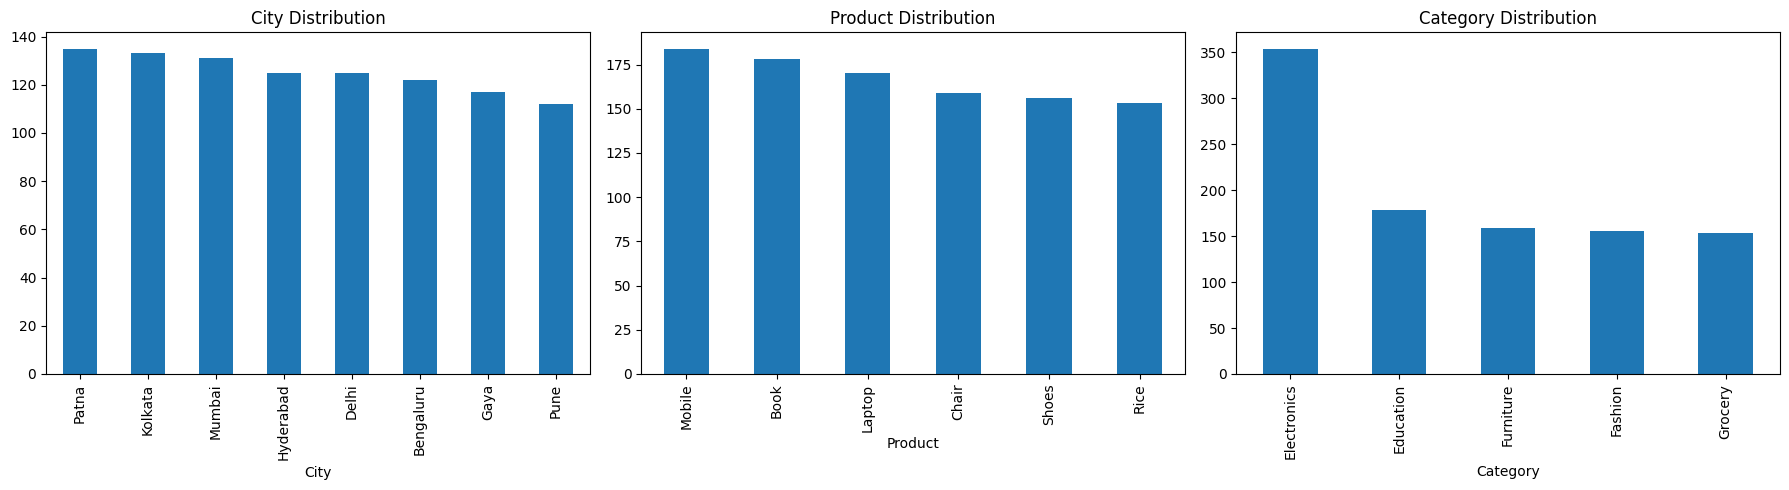

In [54]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['City'].value_counts().plot(kind='bar', ax=axes[0], title='City Distribution')
df['Product'].value_counts().plot(kind='bar', ax=axes[1], title='Product Distribution')
df['Category'].value_counts().plot(kind='bar', ax=axes[2], title='Category Distribution')

plt.tight_layout()
plt.show()

**Categorical Field Summary Statistics**
The primary categorical dimensions are Gender, City, Product, and Category.

* **Order_ID & Customer_ID:** It exhibits very high cardinality with 992 unique values among 1,000 transactions,  However, a small number of duplicate order IDs exist 9 times. Since Order_ID is an identifieris not a measurable variable, traditional distribution analysis is not applicable.
  
* **Customer_Name:** Customer Name shows a varied distribution with many unique customers and a few repeat buyers, indicating that sales are generated from both new and returning customers.
 
* **Balanced Customer Demographics:** The gender split is virtually 1:1 (51.1% Male vs. 48.9% Female), indicating no gender bias in customer acquisition.

* **Geographic Spread:** Transactions are evenly distributed across Tier-1 and Tier-2 Indian cities, with Patna (13.5%), Kolkata (13.3%), and Mumbai (13.1%) leading. Pune has the lowest representation (9.9%), and 13 records (1.3%) have missing city entries.

* **Product Dominance:** Product sales are well distributed across all six products, with Mobile (18.4%) being the most ordered item and Rice (15.3%) the least. The small variation in percentages indicates balanced customer demand and a diversified product portfolio. Electronics products (Mobile and Laptop) collectively account for 35.4% of orders, highlighting strong consumer preference for technology products.

* **Category Dominance:** Electronics accounts for more than a third of total orders (35.4%) and total revenue (₹5.08 Cr, or 36.4%) because it contains two high-demand product lines (Mobile and Laptop). The remaining single-SKU categories (Education, Furniture, Fashion, Grocery) share the remaining market evenly at ~15% to 18% each.

## Univariate , Bivariate Analysis :

#### Chart - 1 : Total Sales Distribution (Target Variable)


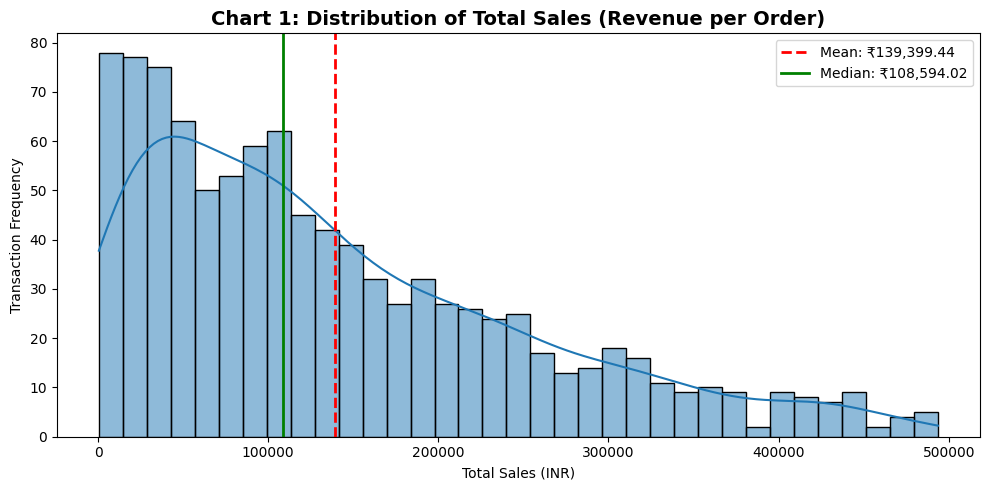

In [108]:
fig, ax =plt.subplots(figsize=(10, 5))
sns.histplot(df['Total_Sales'], kde=True, bins=35,  ax=ax)
ax.axvline(df['Total_Sales'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: ₹{df['Total_Sales'].mean():,.2f}")
ax.axvline(df['Total_Sales'].median(), color='green', linestyle='-', linewidth=2, label=f"Median: ₹{df['Total_Sales'].median():,.2f}")
ax.set_title('Chart 1: Distribution of Total Sales (Revenue per Order)', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Sales (INR)')
ax.set_ylabel('Transaction Frequency')
ax.legend()
plt.tight_layout()
plt.show()


**Insights:** The distribution is positively skewed with a pronounced right-tail extension. The mean sales value (₹139,399) sits noticeably above the median (₹108,594), driven by high-value transactions exceeding ₹350,000 in Electronics and IT hardware purchases.


#### Chart - 2 :  Gender Breakdown 


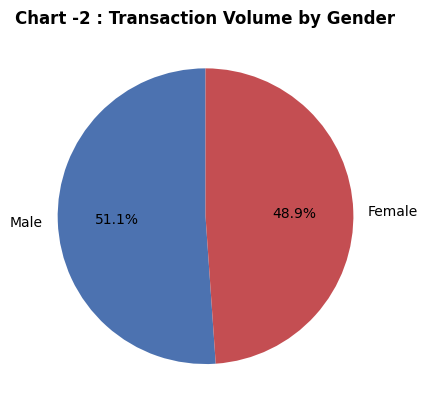

In [109]:
gender_counts = df['Gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['#4c72b0', '#c44e52'], startangle=90)
plt.title('Chart -2 : Transaction Volume by Gender', fontweight='bold')
plt.show()


**Insights :** Gender distribution analysis was conducted to understand transaction participation across customer segments. Gender representation is evenly split (50.5% Female, 49.5% Male)

## Multivariate Analysis & Correlation 

#### Chart - 3 : Total Sales Revenue Generated Across Categories


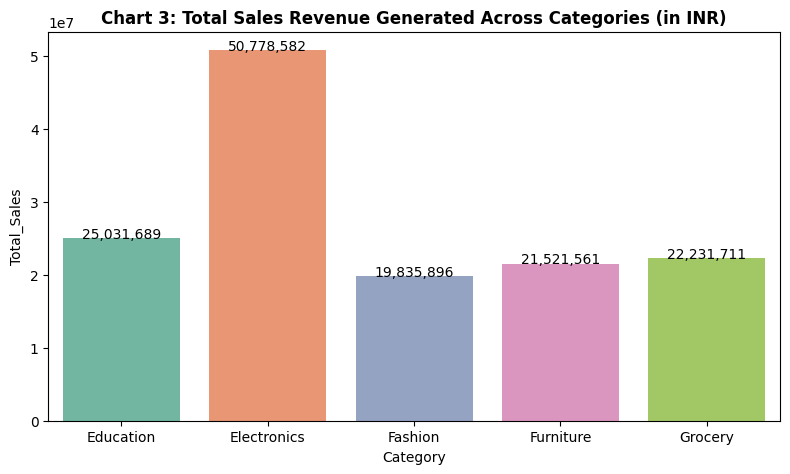

In [111]:
plt.figure(figsize=(8,5))
ax=sns.barplot(
    data=df.groupby('Category', as_index=False)['Total_Sales'].sum(),
    x='Category',y='Total_Sales',palette='Set2')

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():,.0f}',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center')

plt.title('Chart 3: Total Sales Revenue Generated Across Categories (in INR)', fontweight='bold')
plt.tight_layout()
plt.show()

**Insights :** Electronics delivers the largest revenue share (over ₹), followed by Education and Furniture. While Grocery orders match Fashion in volume, their gross ticket generation is comparable due to bulk quantity purchasing.


#### Chart - 4 : Units Sold Across Product Categories

In [23]:
quantity_order = df.groupby('Category')['Quantity'].sum().sort_values(ascending=False)
quantity_order

Category
Electronics    1978
Education       977
Furniture       855
Grocery         826
Fashion         799
Name: Quantity, dtype: int64

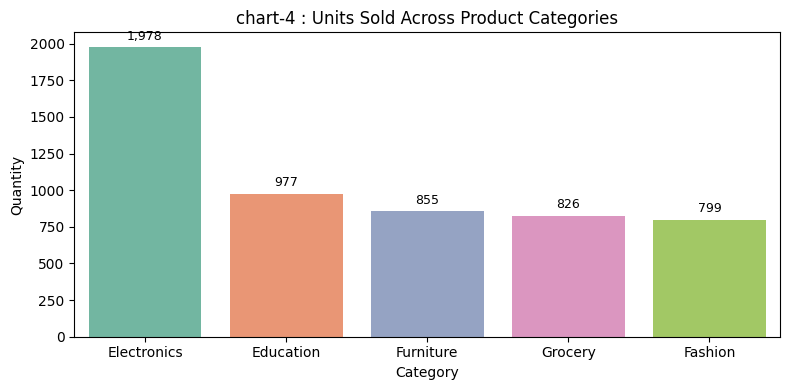

In [112]:
plt.figure(figsize=(8,4))
sns.barplot(x=quantity_order.index,y=quantity_order.values,palette='Set2')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.ylabel("Quantity")
plt.title("chart-4 : Units Sold Across Product Categories")
plt.tight_layout()
plt.show()

**Insights :** Electronics is the clear market leader with 1,978 units sold, contributing more than twice the volume of any other category. The remaining categories show relatively similar demand levels, with Fashion recording the lowest quantity. This suggests a strong dependence on Electronics and highlights opportunities to improve sales in lower-performing categories.

#### Chart - 5 : City-wise Total Sales

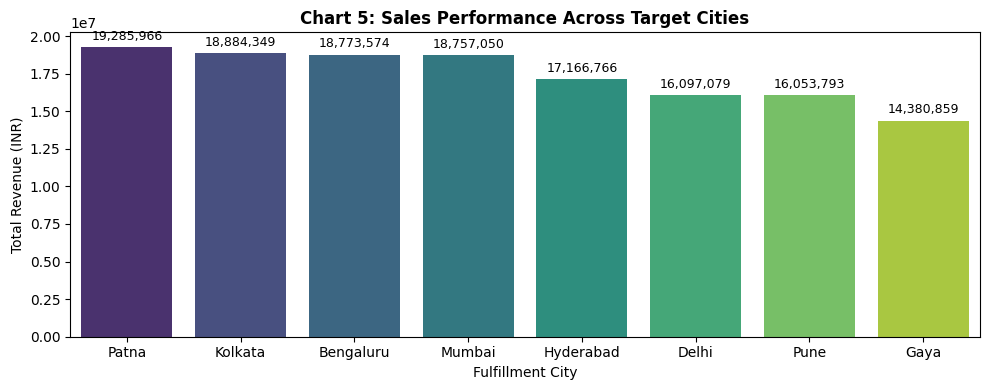

In [113]:
plt.figure(figsize=(10, 4))
city_stats = df.groupby('City')['Total_Sales'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=city_stats, x='City', y='Total_Sales', palette='viridis')
plt.title('Chart 5: Sales Performance Across Target Cities', fontweight='bold')
plt.ylabel('Total Revenue (INR)')
plt.xlabel('Fulfillment City')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


**Insights :** Sales performance varies across cities, with the leading city contributing the largest share of revenue. This indicates that customer demand is not evenly distributed geographically. High-performing cities should be prioritized for inventory and fulfillment planning, while lower-performing cities represent potential growth opportunities through targeted market development initiatives.


#### Chart - 6 : Customer Distribution Across Demographic Age Cohorts

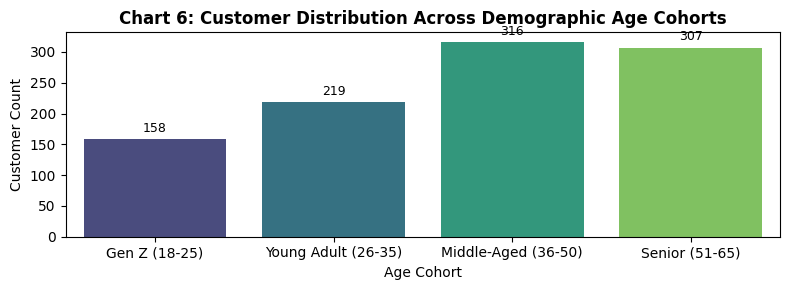

In [114]:
df['Age_Group'] = pd.cut(
    df['Age'], 
    bins=[17, 25, 35, 50, 65], 
    labels=['Gen Z (18-25)', 'Young Adult (26-35)', 'Middle-Aged (36-50)', 'Senior (51-65)'])

plt.subplots(figsize=(8, 3))
age_cohort_order = ['Gen Z (18-25)', 'Young Adult (26-35)', 'Middle-Aged (36-50)', 'Senior (51-65)']
sns.countplot(data=df, x='Age_Group', order=age_cohort_order, palette='viridis')
plt.title('Chart 6: Customer Distribution Across Demographic Age Cohorts', fontweight='bold')
plt.xlabel('Age Cohort')
plt.ylabel('Customer Count')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


**Insights :** The age cohort analysis revealed the demographic composition of the customer base. By grouping customers into Gen Z, Young Adult, Middle-Aged, and Senior segments, the analysis identified the most represented age group and uncovered opportunities for age-specific marketing strategies. Understanding customer age distribution helps optimize product positioning, promotional campaigns, and customer engagement initiatives.

#### Chart - 7 : Purchasing History across Gender

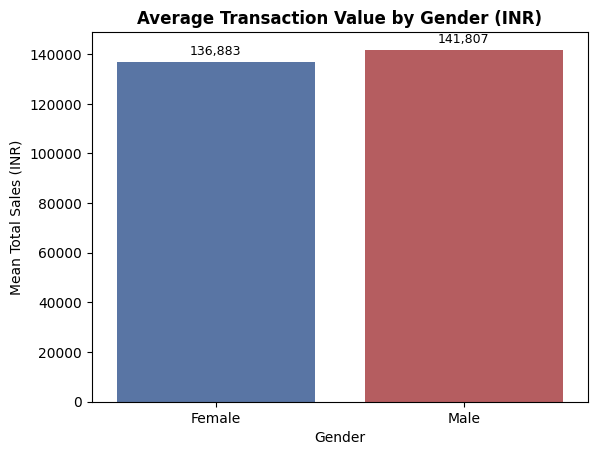

In [75]:
sns.barplot(data=df, x='Gender', y='Total_Sales', estimator=np.mean, palette=['#4c72b0', '#c44e52'], ci=None)
plt.title('Average Transaction Value by Gender (INR)', fontweight='bold')
plt.ylabel('Mean Total Sales (INR)')
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.show()

**Insights :** The visualization highlights the share of total transactions contributed by each gender, helping identify dominant customer groups and informing targeted marketing and product strategies.

#### Chart - 8 : Monthly Sales Trend Line Plot


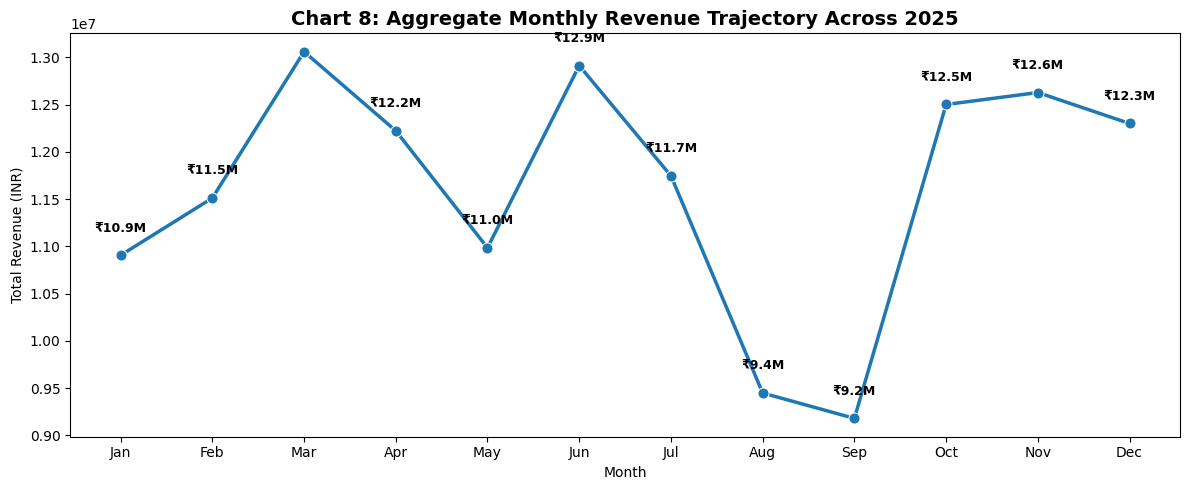

In [105]:
fig, ax =plt.subplots(figsize=(12, 5))
monthly_sales = df.groupby('Order_Month')['Total_Sales'].agg(['sum', 'count']).reset_index()
months_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.lineplot(data=monthly_sales, x='Order_Month', y='sum', marker='o', linewidth=2.5, markersize=8, ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months_labels)
ax.set_title('Chart 8: Aggregate Monthly Revenue Trajectory Across 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Total Revenue (INR)')
for x, y in zip(monthly_sales['Order_Month'], monthly_sales['sum']):
    ax.annotate(f"₹{y/1e6:.1f}M", (x, y + 250000), ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


**Insights :** Revenue peaks during festive and end-of-quarter cycles (March, june, October to December), while  (Aug-sep) experience low transaction volume.


#### Chart - 9 :  Regional Category Dominance Across Cities

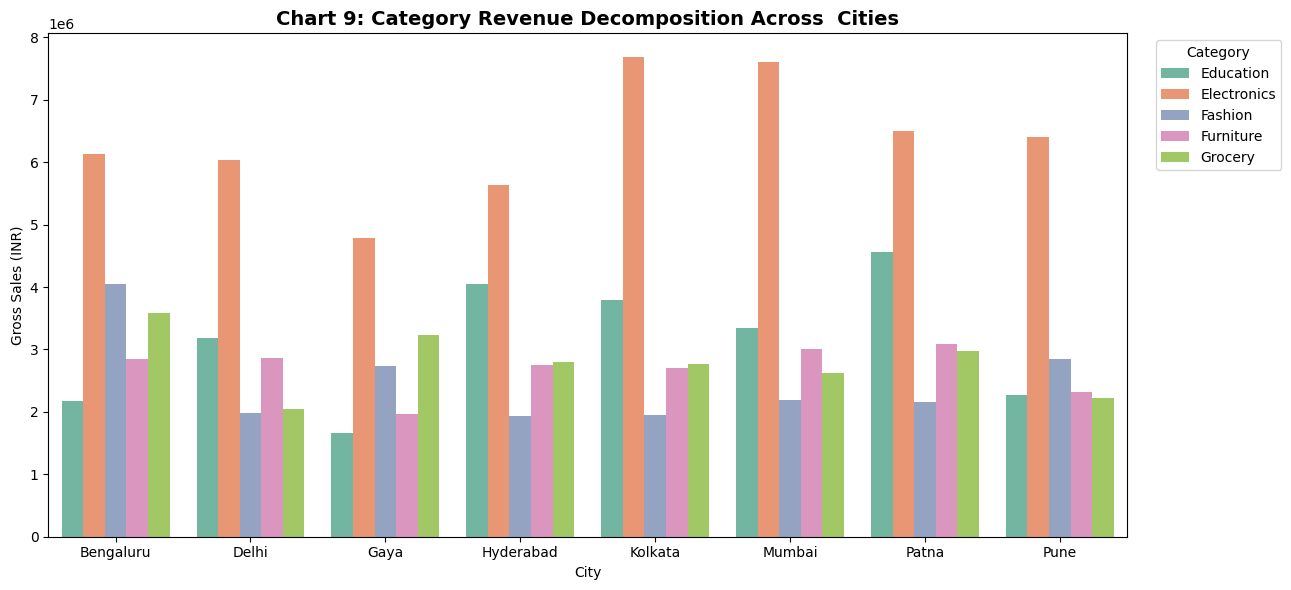

In [107]:
plt.figure(figsize=(13, 6))
city_cat_sales = df.groupby(['City', 'Category'])['Total_Sales'].sum().reset_index()
sns.barplot(data=city_cat_sales, x='City', y='Total_Sales', hue='Category', palette='Set2')
plt.title('Chart 9: Category Revenue Decomposition Across  Cities', fontsize=14, fontweight='bold')
plt.xlabel('City')
plt.ylabel('Gross Sales (INR)')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Insights :** Electronics leads across all cities. Kolkata and Patna demonstrate elevated Furniture and Education revenue, while Bengaluru and Delhi exhibit strong Fashion and Electronics velocity.


#### Chart - 10 : Total sales vs. Unit Price Interaction 


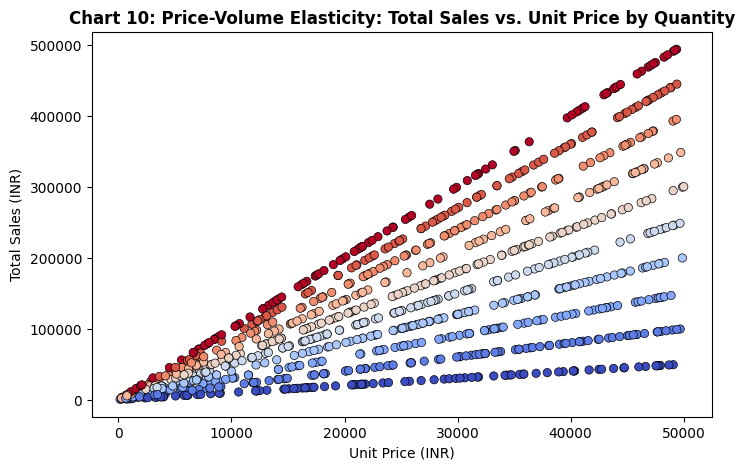

In [145]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,y='Total_Sales',x='Unit_Price',c=df['Quantity'], cmap='coolwarm', edgecolors='black')
plt.xlabel('Unit Price (INR)')
plt.ylabel('Total Sales (INR)')
plt.title('Chart 10: Price-Volume Elasticity: Total Sales vs. Unit Price', fontweight='bold')
plt.show()


**Insights :** Points fan out in distinct linear vectors, where each ray corresponds to a discrete quantity multiplier (1x through 10x). High unit-price items combined with large quantities drive top-tier transaction revenue.


#### Chart - 11 :  Correlation Heatmap

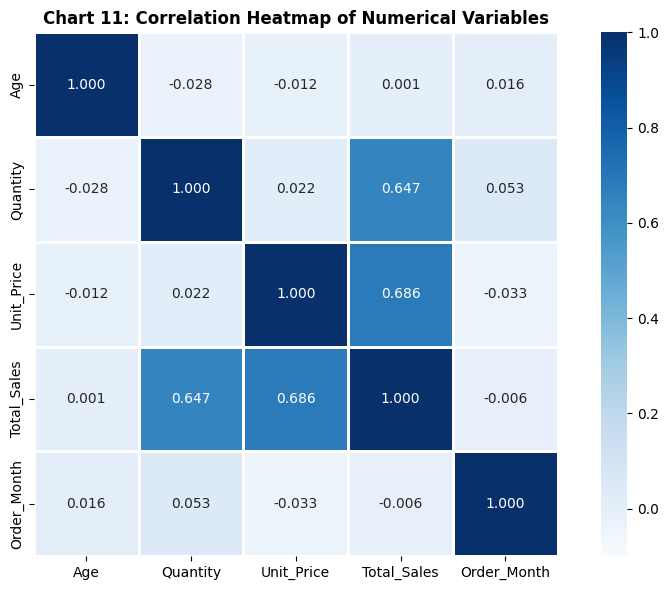

In [157]:
fig, ax = plt.subplots(figsize=(9, 6))
num_cols = ['Age', 'Quantity', 'Unit_Price', 'Total_Sales', 'Order_Month']
corr_matrix = df[num_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=-0.1, vmax=1.0, 
            square=True, linewidths=1, ax=ax)
ax.set_title('Chart 11: Correlation Heatmap of Numerical Variables',  fontweight='bold')
plt.tight_layout()
plt.show()


**Insights** Total_Sales shows strong positive correlation with `Unit_Price` and `Quantity` . `Age` and temporal indicators exhibit near-zero correlation with total sales.


#### Chart - 12 :  Correlation Heatmap

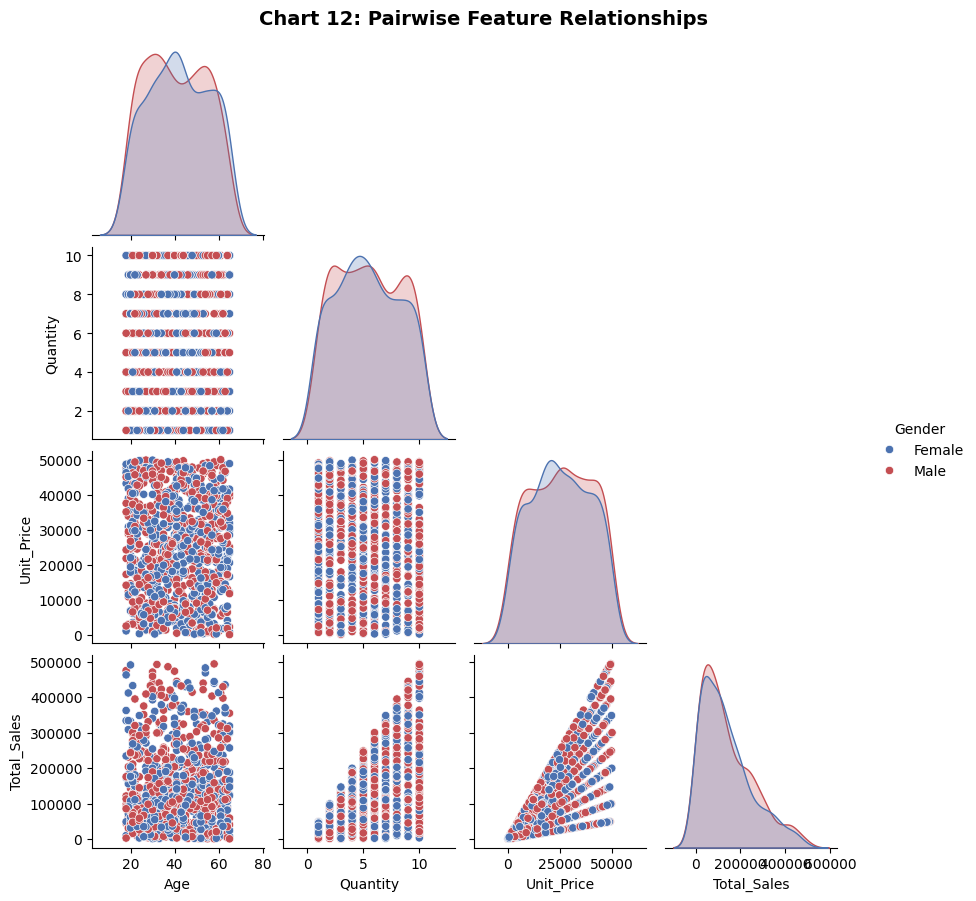

In [160]:
pairplot_cols = ['Age', 'Quantity', 'Unit_Price', 'Total_Sales', 'Gender']
g = sns.pairplot(df[pairplot_cols], hue='Gender', palette=['#4c72b0', '#c44e52'], 
                 diag_kind='kde', corner=True, height=2.2)
g.fig.suptitle('Chart 12: Pairwise Feature Relationships', y=1.02, fontsize=14, fontweight='bold')
plt.show()


**Insights :** A pair plot visualizes pairwise bivariate distributions alongside diagonal KDE densities, evaluating demographic separation and feature relationships across genders.

Male and Female customer data points overlap uniformly across all numeric variables. This confirms identical spending behaviors between genders, ruling out demographic bias in transactional ticket size.

